# Quantização de Imagens

Aluno: Pablo Vinícius Abdon Oliveira

Utilizando como base o notebook desenvolvido em sala:
Carregue uma imagem de sua escolha e converta-a para tons de cinza.
A partir da imagem em tons de cinza, gere versões quantizadas utilizando:

    1 bit → 2 níveis de intensidade;
    2 bits → 4 níveis;
    4 bits → 16 níveis;
    8 bits → 256 níveis.

Exiba, em uma única figura, a imagem original em tons de cinza e as quatro imagens quantizadas, identificando em cada uma a quantidade de bits utilizada. Adicione ao notebook uma célula de texto respondendo brevemente:

O que acontece com os detalhes e com as transições de intensidade da imagem à medida que reduzimos o número de bits?
Salve a figura gerada como quantizacao.png.

Importante: implemente a quantização utilizando operações com os valores dos pixels e NumPy, sem utilizar uma função pronta específica para quantização.

Entrega
Faça o commit do notebook .ipynb e da imagem quantizacao.png no seu respectivo repositório do GitHub.

In [1]:
import cv2
from google.colab.patches import cv2_imshow ## Só precisa se usando o colab
import matplotlib.pyplot as plt

### Pegando a imagem direto da internet

In [2]:
!wget "https://external-preview.redd.it/botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=pjpg&auto=webp&s=82aa4da521335ffa2c96f9a360922745198365ef"

--2026-08-26 19:29:22--  https://external-preview.redd.it/botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=pjpg&auto=webp&s=82aa4da521335ffa2c96f9a360922745198365ef
Resolving external-preview.redd.it (external-preview.redd.it)... 151.101.1.140, 151.101.65.140, 151.101.129.140, ...
Connecting to external-preview.redd.it (external-preview.redd.it)|151.101.1.140|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39503 (39K) [image/jpeg]
Saving to: ‘botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=pjpg&auto=webp&s=82aa4da521335ffa2c96f9a360922745198365ef’

botw-made-some-pixe 100%[===================>]  38.58K  --.-KB/s    in 0.007s  

2026-08-26 19:29:22 (5.78 MB/s) - ‘botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=p

### Mostrando a imagem

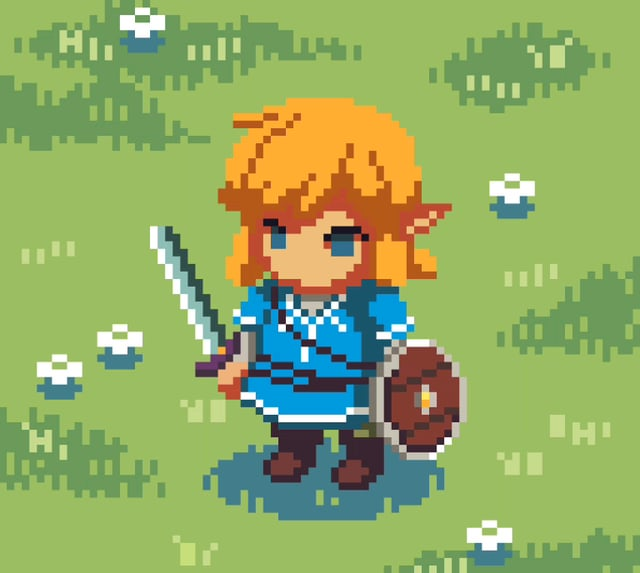

In [3]:
img = cv2.imread('botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=pjpg&auto=webp&s=82aa4da521335ffa2c96f9a360922745198365ef')

cv2_imshow(img)

In [4]:
img.shape

(573, 640, 3)

### Printando os valores RGB de cada pixel

In [5]:
print(img)

[[[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]]

 [[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]]

 [[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]]

 ...

 [[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 95 191 154]
  [ 96 191 154]
  [ 96 191 154]]

 [[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 95 191 154]
  [ 96 191 154]
  [ 96 191 154]]

 [[ 98 190 155]
  [ 98 190 155]
  [ 98 190 155]
  ...
  [ 95 191 154]
  [ 96 190 155]
  [ 96 190 155]]]


### Diminuindo o brilho dividindo cada pixel por 2

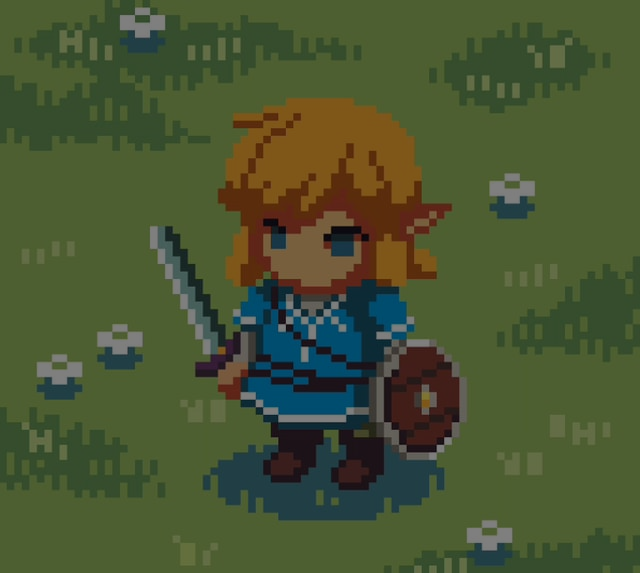

In [6]:
cv2_imshow(img/2)

### Invertendo a imagem com uma operação matricial

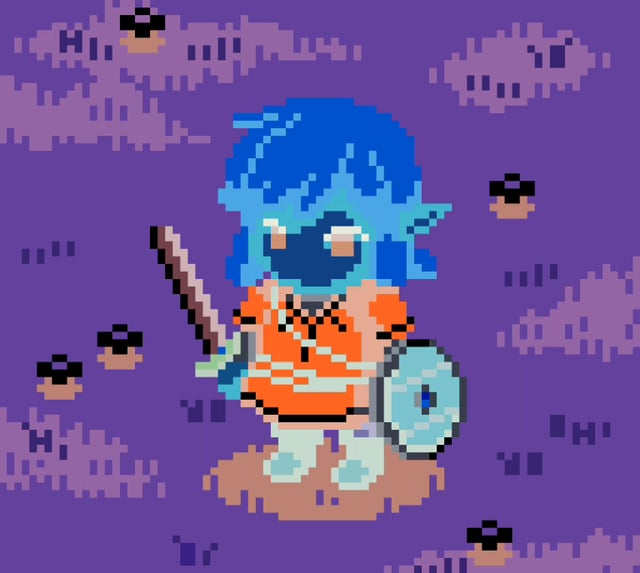

In [7]:
img_inverted = 255 - img

cv2_imshow(img_inverted)

### Separando os canais de cor da imagem

In [8]:
B, G, R = cv2.split(img)

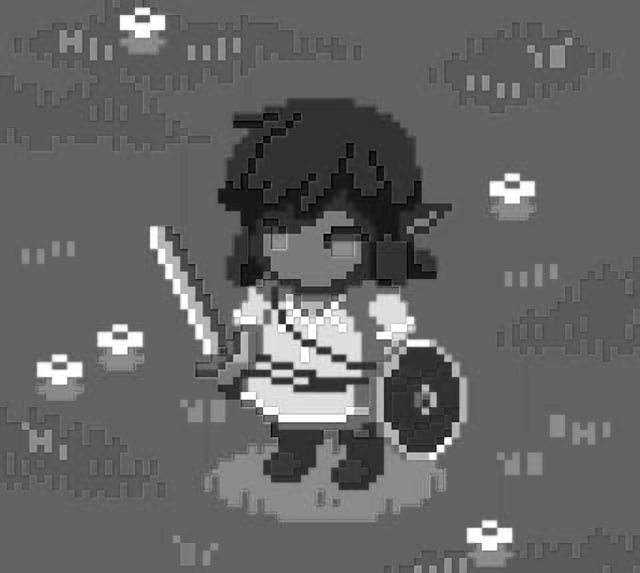

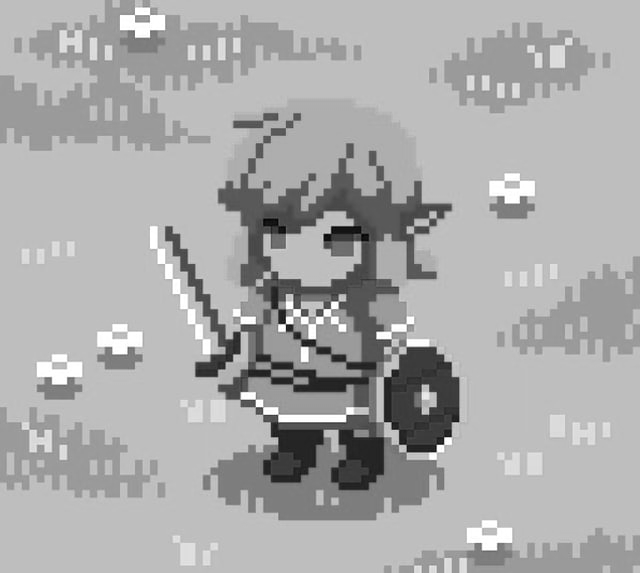

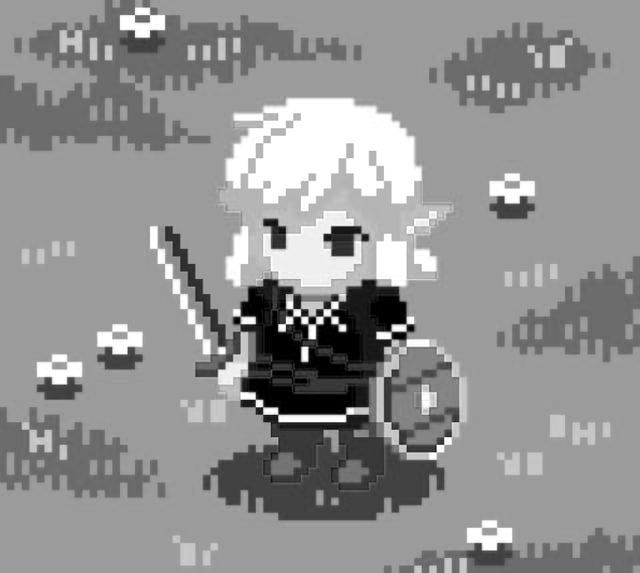

In [9]:
for img in list((B,G,R)):
    cv2_imshow(img)

### Imagem em diferentes níveis de intensidade

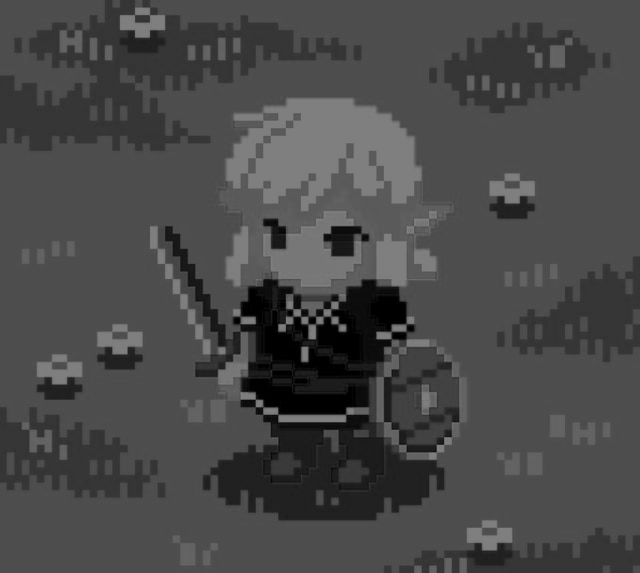

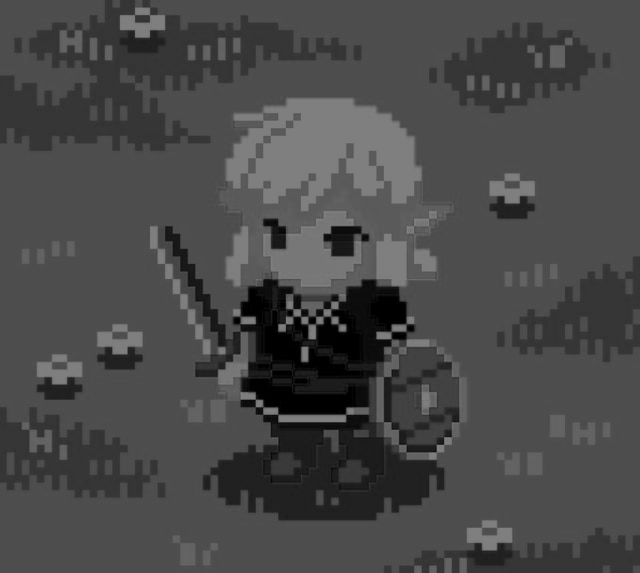

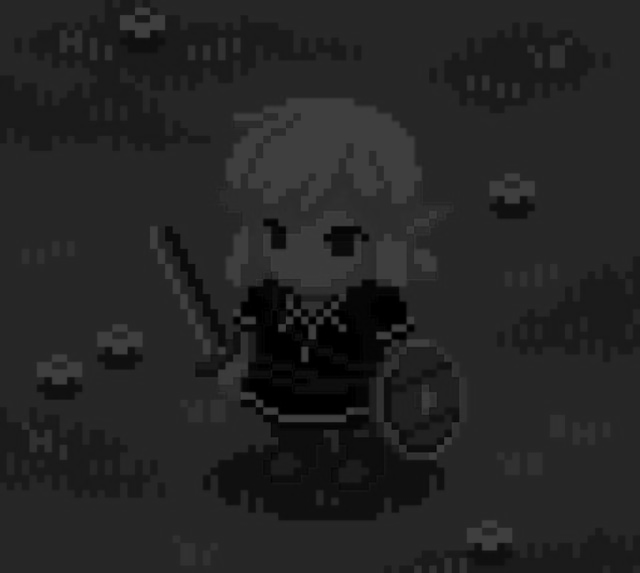

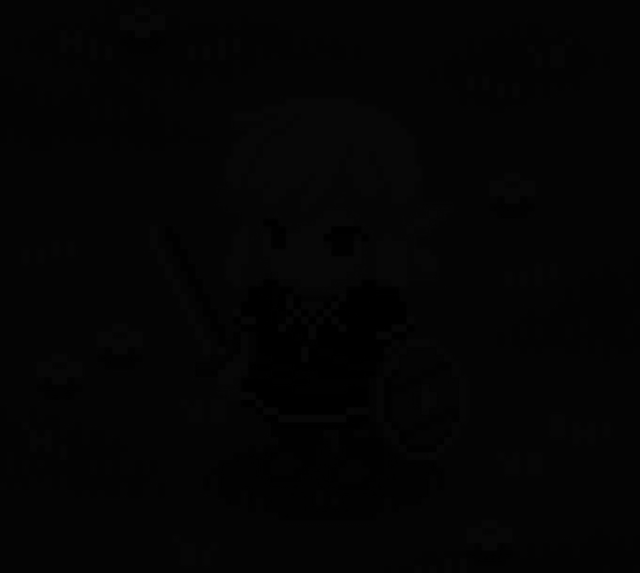

In [16]:

fatores_e_niveis = {
    '1': 2,
    '2': 4,
    '4': 16,
    '8': 256}

quantizacoes = []

for i, (bits, niveis) in enumerate(fatores_e_niveis.items()):
  fator = (niveis // int(bits))
  quantizacoes.append((img // fator))

for img in quantizacoes:
    cv2_imshow(img)

### Exibindo tudo junto

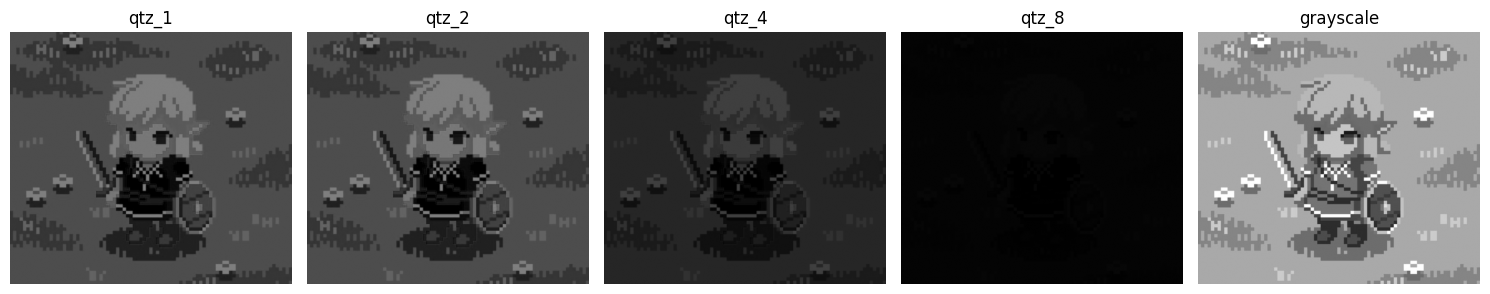

In [20]:
import cv2
import matplotlib.pyplot as plt

# Imagem cinza
img_cinza = cv2.imread('botw-made-some-pixel-art-of-link-it-was-my-first-time-v0-pV9bYGNnIhjAioIXl-JgA6WerO5ajHRKCA-zhVWrTRM.png?width=640&crop=smart&format=pjpg&auto=webp&s=82aa4da521335ffa2c96f9a360922745198365ef',
                       cv2.IMREAD_GRAYSCALE)

img_arr = [('qtz_1', quantizacoes[0]), ('qtz_2', quantizacoes[1]), ('qtz_4', quantizacoes[2]), ('qtz_8', quantizacoes[3]), ('grayscale', img_cinza)]

plt.figure(figsize=(15, 8))

for i, (title, img) in enumerate(img_arr):

    plt.subplot(1, 5, i+1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)

    plt.title(title, fontsize=12)

    plt.axis('off')

plt.tight_layout()
plt.show()
